# Phase 2 — Automated Galaxy Image Acquisition (RGB Cutouts & Multi-Band FITS)

Welcome to **Phase 2** of the **SDSS Galaxy Morphology & Scaling Relations Atlas**! In Phase 1, we downloaded real galaxy measurements into our SQLite database (`data/galaxy_atlas.db`). In Phase 2, we attach **real telescope images** to those galaxies using two complementary pipelines inside `src/imaging.py`:

1. **Track A — Lightweight SkyServer RGB Cutouts (`SkyServerRGBDownloader`)**:
   - Fetches `128 × 128` px color JPEG cutouts at SDSS's native `0.396 arcsec/px` scale (`50.7" × 50.7"` field of view) from SDSS DR17's `SkyServerWS/ImgCutout/getjpeg` service.
   - Multi-threaded, **100% resumable** (skips already-downloaded galaxies automatically), validates every image with `Pillow`, and logs each file in the `images` table of `data/galaxy_atlas.db`.
   - These standardized `128 × 128` RGB cutouts will feed our **Phase 3 Hubble Sequence CNN**.

2. **Track B — Calibrated Multi-Band FITS Showcase (`MultiBandFITSProcessor`)**:
   - Selects a balanced showcase subset of bright, nearby elliptical and spiral galaxies.
   - Downloads real raw scientific **FITS** frames in three color filters (`g` = green/blue, `r` = red, `i` = near-infrared) from SDSS SAS.
   - Uses `astropy.wcs.WCS` + `astropy.nddata.Cutout2D` to crop each galaxy accurately in sky coordinates `(ra, dec)`.
   - Detects and masks bad pixels (`NaN`/`Inf`) using sigma-clipped sky background estimation and subtracts the sky background.
   - Synthesizes astronomical **Lupton arcsinh-stretched RGB** images via `astropy.visualization.make_lupton_rgb(i, r, g)` so both bright galactic cores and faint outer spiral arms remain visible at once!

---
## Step 1: Configuration & Safe Run Toggles

Leave `RUN_LIVE_DOWNLOAD = False` to inspect the already-downloaded images and database records immediately without making network requests. Flip `RUN_LIVE_DOWNLOAD = True` whenever you want to download more RGB cutouts (for example, all remaining galaxies in the 2,489-galaxy catalog) or expand the FITS showcase.

In [1]:
import json
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.io import fits
from PIL import Image

from src.config import ProjectConfig
from src.database import GalaxyDatabase
from src.imaging import (
    MultiBandFITSProcessor,
    SkyServerRGBDownloader,
    plot_showcase_comparison,
)

config = ProjectConfig()
config.ensure_directories()

print("Imaging configuration:")
print(json.dumps(config.imaging_metadata(), indent=2))
print("RGB cutouts dir: ", config.rgb_cutouts_dir)
print("FITS cutouts dir:", config.fits_cutouts_dir)
print("Lupton RGB dir:  ", config.lupton_rgb_dir)

Imaging configuration:
{
  "cutout_size_px": 128,
  "pixel_scale_arcsec": 0.396,
  "fits_showcase_count": 12,
  "lupton_q": 8.0,
  "lupton_stretch": 0.5
}
RGB cutouts dir:  C:\Things\Astrophysics_Antigravity_Pj\AstrophysicsProjectRepo\data\processed\rgb_cutouts
FITS cutouts dir: C:\Things\Astrophysics_Antigravity_Pj\AstrophysicsProjectRepo\data\processed\fits_cutouts
Lupton RGB dir:   C:\Things\Astrophysics_Antigravity_Pj\AstrophysicsProjectRepo\data\processed\lupton_rgb


---
## Step 2: Run (or Resume) SkyServer RGB & FITS Showcase Acquisition

Because `SkyServerRGBDownloader` checks `db.get_galaxies_missing_images('rgb_cutout')` and validates existing JPEGs on disk, you can run it in batches (e.g., `RGB_LIMIT = 200` at a time, or `RGB_LIMIT = None` for all remaining galaxies) without ever redoing finished work.

In [2]:
RUN_LIVE_DOWNLOAD = False  # Set True to fetch additional cutouts or FITS frames live
RGB_LIMIT = 50             # Set to None to fetch all remaining galaxies in data/galaxy_atlas.db
FITS_SHOWCASE_COUNT = 6    # Balanced half early-type + half late-type

with GalaxyDatabase(config.db_path) as db:
    if RUN_LIVE_DOWNLOAD:
        rgb_dl = SkyServerRGBDownloader(config)
        rgb_stats = rgb_dl.download_for_database(db, limit=RGB_LIMIT)
        print("RGB download stats:", rgb_stats)

        fits_proc = MultiBandFITSProcessor(config)
        fits_stats = fits_proc.run_showcase(db, count=FITS_SHOWCASE_COUNT)
        print("FITS showcase stats:", {k: v for k, v in fits_stats.items() if k != "diagnostics"})
    else:
        print("RUN_LIVE_DOWNLOAD=False -> reading existing registered image assets from SQLite.")

    images_summary = db.get_images_summary()
    table_counts = db.get_table_counts()

print("Database table counts:", table_counts)
display(images_summary)

RUN_LIVE_DOWNLOAD=False -> reading existing registered image assets from SQLite.
Database table counts: {'galaxies': 2489, 'images': 308, 'predictions': 3057, 'metadata': 15}


,image_type,band,image_count,avg_pixel_scale_arcsec,avg_width_px,avg_height_px
0,fits_cutout,g,6,0.396,128.0,128.0
1,fits_cutout,i,6,0.396,128.0,128.0
2,fits_cutout,r,6,0.396,128.0,128.0
3,lupton_rgb,gri,6,0.396,128.0,128.0
4,rgb_cutout,gri,284,0.396,128.0,128.0


---
## Step 3: Inspect the `v_galaxy_dashboard` View Join

Our normalized SQLite database keeps image file paths in the `images` table linked by `objID`, while `v_galaxy_dashboard` automatically joins each galaxy's physical properties with its SkyServer RGB cutout path for Phase 3 & Phase 4.

In [3]:
with GalaxyDatabase(config.db_path) as db:
    joined_df = db.query_df(
        """
        SELECT objID, redshift, color_gr, log_stellar_mass, concentration, morph_proxy, rgb_image_path
        FROM v_galaxy_dashboard
        WHERE rgb_image_path IS NOT NULL
        ORDER BY objID
        LIMIT 10
        """
    )

display(joined_df)

,objID,redshift,color_gr,log_stellar_mass,concentration,morph_proxy,rgb_image_path
0,1237645879551066262,0.032125,0.65768,9.295615,2.503365,late,data/processed/rgb_cutouts/1237645879551066262...
1,1237645879577936138,0.074298,0.70102,10.185770,2.223676,late,data/processed/rgb_cutouts/1237645879577936138...
2,1237645942905438473,0.025475,0.64994,9.779433,2.041748,late,data/processed/rgb_cutouts/1237645942905438473...
3,1237645942905438495,0.036167,0.59201,9.583373,2.223273,late,data/processed/rgb_cutouts/1237645942905438495...
4,1237645942905897107,0.082959,1.14218,10.605690,3.130720,early,data/processed/rgb_cutouts/1237645942905897107...
5,1237645942905897117,0.082322,1.09073,10.661030,3.162259,early,data/processed/rgb_cutouts/1237645942905897117...
6,1237645943973609616,0.072549,0.70025,9.985489,2.166275,late,data/processed/rgb_cutouts/1237645943973609616...
7,1237645943973609618,0.074451,0.96599,10.398250,2.773959,early,data/processed/rgb_cutouts/1237645943973609618...
8,1237645943975837722,0.066758,0.73354,10.694950,2.151588,late,data/processed/rgb_cutouts/1237645943975837722...
9,1237645943976493208,0.036462,0.61812,9.624868,2.139507,late,data/processed/rgb_cutouts/1237645943976493208...


---
## Step 4: Inspect Multi-Band FITS Cutouts (`g`, `r`, `i`) vs. Lupton RGB

Why do astronomers work with scientific **FITS** files instead of only JPEGs?
- **JPEGs** compress light into 8-bit integers (`0–255`), losing faint outer disks and saturating bright galaxy centers.
- **FITS** files preserve floating-point calibrated flux measurements in each wavelength filter (`g`, `r`, `i`) plus **WCS (World Coordinate System)** headers that map every pixel directly to celestial coordinates `(RA, Dec)`.
- By applying **Lupton's arcsinh stretch** (`make_lupton_rgb`), we compress the huge dynamic range gently so faint blue spiral arms and bright red galactic bulges appear together with accurate colors.

Let's inspect the individual `g`, `r`, `i` FITS cutouts alongside the synthesized Lupton RGB composite for one showcase galaxy!

,objID,morph_proxy,redshift,concentration
0,1237648704052527246,late,0.024549,2.183086
1,1237648705122074764,late,0.036472,1.931091
2,1237648703515590916,late,0.049182,2.257619
3,1237648704049905873,early,0.088625,3.277173
4,1237648703515852998,early,0.054747,3.065927
5,1237648703525421273,early,0.066215,3.186893


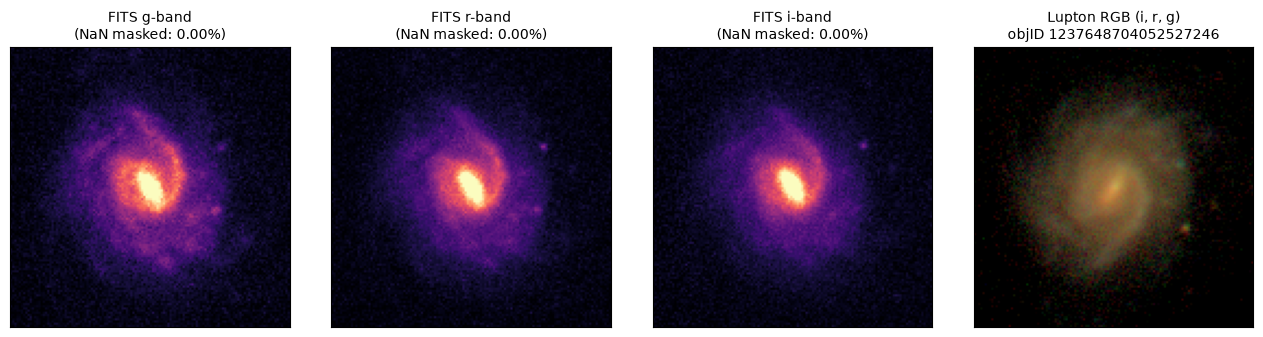

In [4]:
with GalaxyDatabase(config.db_path) as db:
    showcase_ids = db.query_df(
        """
        SELECT DISTINCT g.objID, g.morph_proxy, g.redshift, g.concentration
        FROM galaxies AS g
        INNER JOIN images AS i ON i.objID = g.objID AND i.image_type = 'lupton_rgb'
        ORDER BY g.morph_proxy DESC, g.model_mag_r ASC
        """
    )

display(showcase_ids)

if not showcase_ids.empty:
    demo_id = int(showcase_ids.iloc[0]["objID"])
    fig, axes = plt.subplots(1, 4, figsize=(13, 3.3))
    for idx, band in enumerate(["g", "r", "i"]):
        fits_path = config.fits_cutouts_dir / f"{demo_id}_{band}.fits"
        with fits.open(fits_path) as hdul:
            img_data = hdul[0].data
            nan_frac = hdul[0].header.get("NANFRAC", 0.0)
        vmin, vmax = np.percentile(img_data, [5, 99.5])
        axes[idx].imshow(img_data, origin="lower", cmap="magma", vmin=vmin, vmax=vmax)
        axes[idx].set_title(f"FITS {band}-band\n(NaN masked: {nan_frac:.2%})", fontsize=10)
        axes[idx].set_xticks([])
        axes[idx].set_yticks([])

    lupton_path = config.lupton_rgb_dir / f"{demo_id}_lupton_rgb.png"
    axes[3].imshow(Image.open(lupton_path))
    axes[3].set_title(f"Lupton RGB (i, r, g)\nobjID {demo_id}", fontsize=10)
    axes[3].set_xticks([])
    axes[3].set_yticks([])
    fig.tight_layout()
    plt.show()

---
## Step 5: Side-by-Side Showcase Gallery (SkyServer RGB vs. FITS Lupton RGB)

Finally, let's render and save a clean side-by-side comparison figure (`outputs/figures/phase2_showcase_comparison.png`) comparing SkyServer's pre-rendered cutouts against our custom `Cutout2D` + `make_lupton_rgb` FITS pipeline across early-type and late-type showcase galaxies.

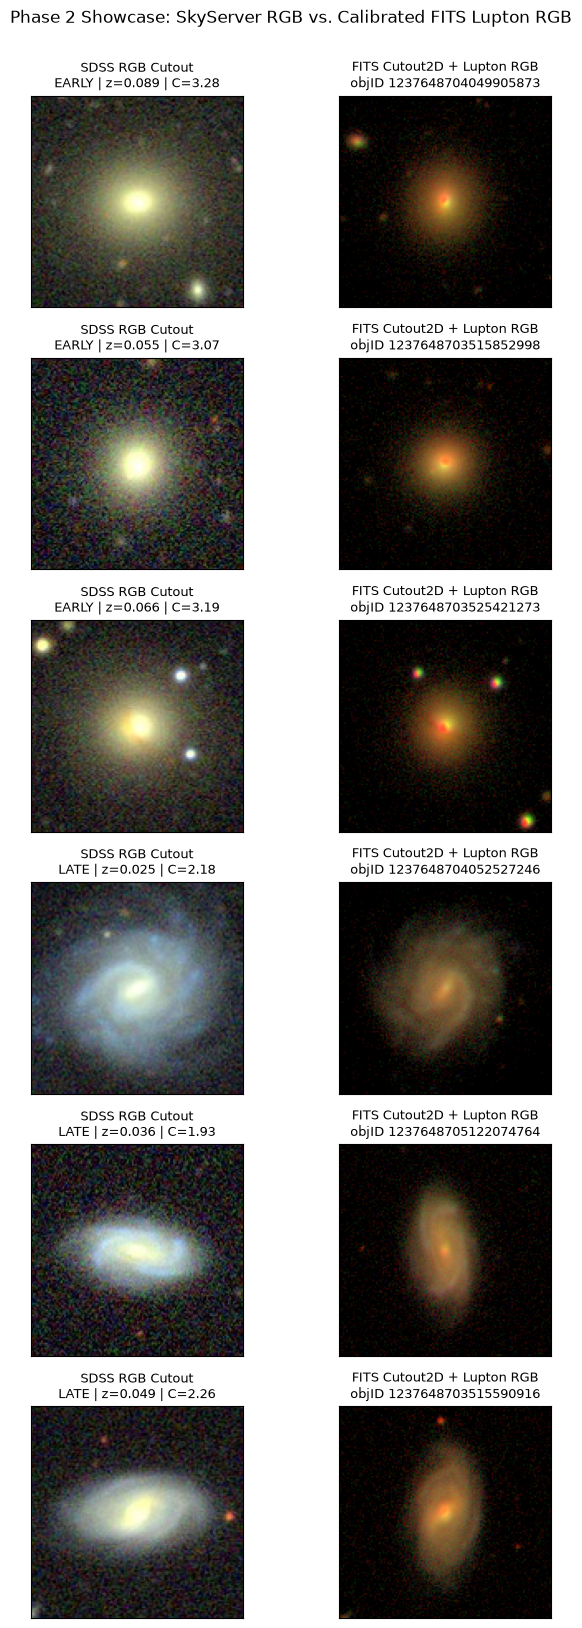

Saved comparison gallery to: C:\Things\Astrophysics_Antigravity_Pj\AstrophysicsProjectRepo\outputs\figures\phase2_showcase_comparison.png


In [5]:
with GalaxyDatabase(config.db_path) as db:
    fig = plot_showcase_comparison(
        db=db,
        config=config,
        output_path=config.figures_dir / "phase2_showcase_comparison.png",
        max_galaxies=6,
    )
plt.show()
print("Saved comparison gallery to:", config.figures_dir / "phase2_showcase_comparison.png")